In [6]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
np.set_printoptions(suppress=True, precision=4)
pd.set_option("display.float_format", "{:.4f}".format)

# Plotting style
plt.style.use("default")
sns.set_theme(context="notebook", style="whitegrid")

# File path (adjust if needed)
PATH = "../../statsbomb_pipeline/data/processed/team/team_season.csv"

# Load data
df = pd.read_csv(PATH)

# Quick sanity checks
display(df.head())
df.info()


,team_id,team_name,matches_played,wins,draws,losses,goals_for,goals_against,shots_for,passes_for,...,ppa_for,f3_entries_for,xg_for,xthreat_for,goal_diff,xg_per_match,xthreat_per_match,goals_per_match,ppa_per_match,f3_entries_per_match
0,1,Arsenal,38,18,14,6,62,33,583,22709,...,791,11551,65.1361,47.1636,29,1.7141,1.2411,1.6316,20.8158,303.9737
1,22,Leicester City,38,23,11,4,67,36,525,15093,...,463,6874,66.2822,53.3115,31,1.7443,1.4029,1.7632,12.1842,180.8947
2,23,Watford,38,11,9,18,36,48,450,16362,...,381,6574,44.0821,35.5666,-12,1.1601,0.9360,0.9474,10.0263,173.0000
3,24,Liverpool,38,16,12,10,62,49,635,21464,...,633,9451,58.3737,48.0583,13,1.5361,1.2647,1.6316,16.6579,248.7105
4,25,Southampton,38,18,9,11,57,41,527,17995,...,581,8287,54.2233,45.4986,16,1.4269,1.1973,1.5000,15.2895,218.0789


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   team_id               20 non-null     int64  
 1   team_name             20 non-null     object 
 2   matches_played        20 non-null     int64  
 3   wins                  20 non-null     int64  
 4   draws                 20 non-null     int64  
 5   losses                20 non-null     int64  
 6   goals_for             20 non-null     int64  
 7   goals_against         20 non-null     int64  
 8   shots_for             20 non-null     int64  
 9   passes_for            20 non-null     int64  
 10  carries_for           20 non-null     int64  
 11  ppa_for               20 non-null     int64  
 12  f3_entries_for        20 non-null     int64  
 13  xg_for                20 non-null     float64
 14  xthreat_for           20 non-null     float64
 15  goal_diff             20 

In [2]:
# Use all numeric columns for PCA
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

# Columns to drop from PCA feature set
drop_cols = ["team_id", "matches_played", "wins", "draws", "losses"]

# Remove unwanted columns *if they exist*
pca_features = [col for col in numeric_cols if col not in drop_cols]

print("PCA feature columns:", pca_features)
print("Number of PCA features:", len(pca_features))

# Subset dataframe for PCA
pca_df = df[pca_features].dropna().copy()
print("PCA data shape:", pca_df.shape)


PCA feature columns: ['goals_for', 'goals_against', 'shots_for', 'passes_for', 'carries_for', 'ppa_for', 'f3_entries_for', 'xg_for', 'xthreat_for', 'goal_diff', 'xg_per_match', 'xthreat_per_match', 'goals_per_match', 'ppa_per_match', 'f3_entries_per_match']
Number of PCA features: 15
PCA data shape: (20, 15)


In [ ]:
# Pairwise scatterplot matrix of numeric variables
sns.pairplot(pca_df, corner=True, diag_kind="hist")
plt.suptitle("Pairwise scatterplots of numeric variables", y=1.02)
plt.show()


In [4]:
# Standardize features (mean 0, variance 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(pca_df)

# Fit PCA with all components (max = number of features)
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# Store explained variance info
explained_variance = pca.explained_variance_
explained_variance_ratio = pca.explained_variance_ratio_
components = pca.components_

print("X_scaled shape:", X_scaled.shape)
print("X_pca shape:", X_pca.shape)

loadings = pd.DataFrame(
    components,
    columns=pca_features,                       # <-- correct list of PCA features
    index=[f"PC{i+1}" for i in range(len(pca_features))]   # <-- correct number of PCs
)

display(loadings.head())


X_scaled shape: (20, 15)
X_pca shape: (20, 15)


,goals_for,goals_against,shots_for,passes_for,carries_for,ppa_for,f3_entries_for,xg_for,xthreat_for,goal_diff,xg_per_match,xthreat_per_match,goals_per_match,ppa_per_match,f3_entries_per_match
PC1,0.280637,-0.219209,0.273663,0.224406,0.221189,0.270186,0.252734,0.282448,0.233286,0.279483,0.282448,0.233286,0.280637,0.270186,0.252734
PC2,-0.196850,0.164892,-0.107609,0.423195,0.420609,0.155143,0.358523,-0.221932,-0.204024,-0.201864,-0.221932,-0.204024,-0.196850,0.155143,0.358523
PC3,-0.136141,0.255123,-0.163310,-0.084717,-0.059924,0.097476,0.062325,-0.171631,0.603809,-0.213423,-0.171631,0.603809,-0.136141,0.097476,0.062325
PC4,0.256594,0.794983,0.340295,0.013369,0.024628,0.034576,-0.080196,0.106323,-0.075876,-0.265252,0.106323,-0.075876,0.256594,0.034576,-0.080196
PC5,-0.162582,0.000173,-0.047071,-0.298051,-0.358228,0.569087,-0.016918,0.094768,-0.161820,-0.095561,0.094768,-0.161820,-0.162582,0.569087,-0.016918


In [7]:
# Eigenvalues and variance breakdown

eigenvalues = pca.explained_variance_              # raw variance for each PC
explained_var = pca.explained_variance_ratio_      # proportion of variance
cumulative_var = np.cumsum(explained_var)

pc_indices = np.arange(1, len(eigenvalues) + 1)

variance_table = pd.DataFrame({
    "PC": pc_indices,
    "Eigenvalue": eigenvalues,
    "Prop_Var": explained_var,
    "Cum_Prop_Var": cumulative_var
})

variance_table["Prop_Var_%"] = variance_table["Prop_Var"] * 100
variance_table["Cum_Prop_Var_%"] = variance_table["Cum_Prop_Var"] * 100

variance_table


,PC,Eigenvalue,Prop_Var,Cum_Prop_Var,Prop_Var_%,Cum_Prop_Var_%
0,1,11.0414,0.6993,0.6993,69.9289,69.9289
1,2,2.3551,0.1492,0.8484,14.9157,84.8446
2,3,0.9189,0.0582,0.9066,5.8195,90.6640
3,4,0.6211,0.0393,0.9460,3.9338,94.5978
4,5,0.5390,0.0341,0.9801,3.4138,98.0116
5,6,0.1690,0.0107,0.9908,1.0702,99.0818
6,7,0.0903,0.0057,0.9965,0.5720,99.6538
7,8,0.0484,0.0031,0.9996,0.3065,99.9603
8,9,0.0063,0.0004,1.0000,0.0397,100.0000
9,10,0.0000,0.0000,1.0000,0.0000,100.0000


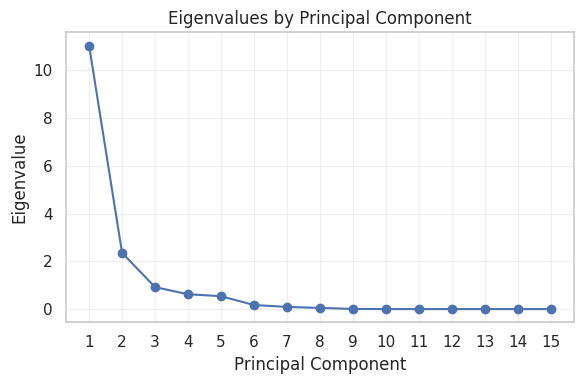

In [8]:
# ---- Eigenvalues vs Principal Component ----

plt.figure(figsize=(6, 4))
plt.plot(pc_indices, eigenvalues, marker="o")
plt.xlabel("Principal Component")
plt.ylabel("Eigenvalue")
plt.title("Eigenvalues by Principal Component")
plt.xticks(pc_indices)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


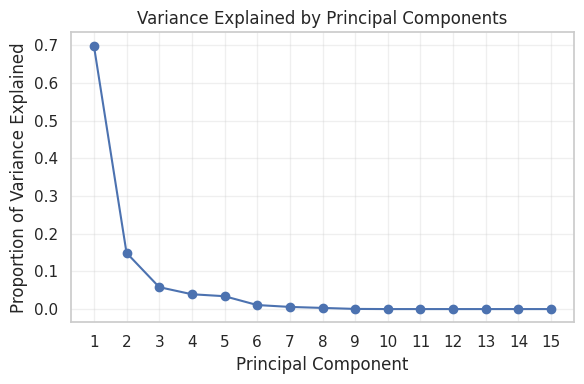

,PC,Eigenvalue,Prop_Var,Cum_Prop_Var,Prop_Var_%,Cum_Prop_Var_%
0,1,11.0414,0.6993,0.6993,69.9289,69.9289
1,2,2.3551,0.1492,0.8484,14.9157,84.8446
2,3,0.9189,0.0582,0.9066,5.8195,90.6640
3,4,0.6211,0.0393,0.9460,3.9338,94.5978
4,5,0.5390,0.0341,0.9801,3.4138,98.0116


In [9]:
# ---- Proportion of variance explained by each PC ----

plt.figure(figsize=(6, 4))
plt.plot(pc_indices, explained_var, marker="o")
plt.xlabel("Principal Component")
plt.ylabel("Proportion of Variance Explained")
plt.title("Variance Explained by Principal Components")
plt.xticks(pc_indices)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
variance_table.head()

In [11]:
loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f"PC{i}" for i in range(1, len(pca_features) + 1)],
    index=pca_features,
)

# Inspect the first few components
loadings.iloc[:, :3]

,PC1,PC2,PC3
goals_for,0.2806,-0.1969,-0.1361
goals_against,-0.2192,0.1649,0.2551
shots_for,0.2737,-0.1076,-0.1633
passes_for,0.2244,0.4232,-0.0847
carries_for,0.2212,0.4206,-0.0599
ppa_for,0.2702,0.1551,0.0975
f3_entries_for,0.2527,0.3585,0.0623
xg_for,0.2824,-0.2219,-0.1716
xthreat_for,0.2333,-0.2040,0.6038
goal_diff,0.2795,-0.2019,-0.2134


In [12]:
# Create column names for PCs
pc_cols = [f"PC{i+1}" for i in range(X_pca.shape[1])]

# Scores for each team on each principal component
pc_scores = pd.DataFrame(
    X_pca,
    columns=pc_cols,
    index=pca_df.index  # keep same index as PCA input
)

# Attach identifiers (adjust columns if different in your df)
id_cols = []
for col in ["team_name", "season", "team_id"]:
    if col in df.columns:
        id_cols.append(col)

pc_scores = pc_scores.join(df[id_cols])

display(pc_scores.head())


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,team_name,team_id
0,5.8135,1.5813,-0.3978,-0.3859,1.5870,0.1293,-0.3997,0.1795,-0.1128,-0.0000,-0.0000,0.0000,0.0000,0.0000,-0.0000,Arsenal,1
1,2.1745,-4.1577,0.4308,-0.2959,-0.1304,-0.5517,-0.1920,0.4019,0.0617,-0.0000,0.0000,-0.0000,0.0000,-0.0000,0.0000,Leicester City,22
2,-3.1040,-0.3709,-1.2427,-0.5084,0.3617,0.1799,0.2397,0.3808,0.0915,0.0000,-0.0000,0.0000,0.0000,0.0000,-0.0000,Watford,23
3,3.6039,0.3739,0.0700,1.0270,0.2704,0.7844,-0.0082,-0.0707,0.0980,0.0000,0.0000,0.0000,0.0000,-0.0000,-0.0000,Liverpool,24
4,1.6233,-0.8071,-0.1795,-0.2155,0.8586,0.0115,-0.1384,-0.3475,0.0751,0.0000,0.0000,-0.0000,-0.0000,0.0000,0.0000,Southampton,25


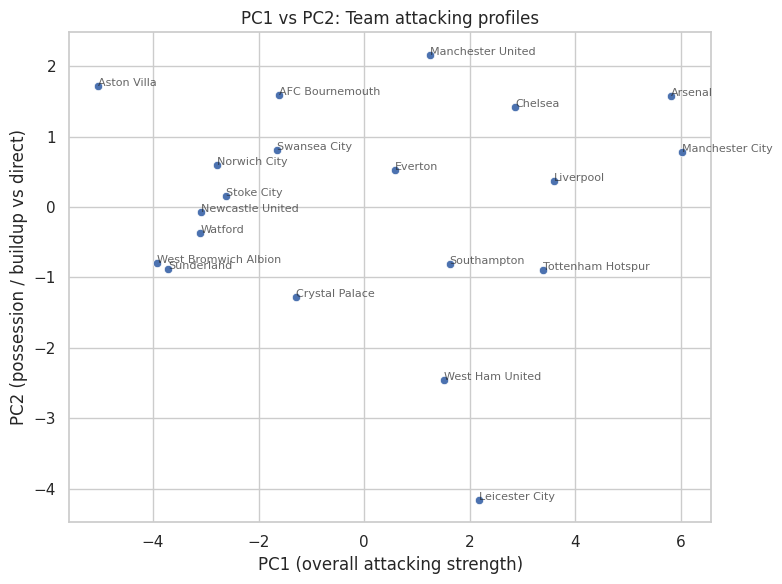

In [13]:
plt.figure(figsize=(8, 6))
ax = sns.scatterplot(
    data=pc_scores,
    x="PC1",
    y="PC2"
)

ax.set_title("PC1 vs PC2: Team attacking profiles")
ax.set_xlabel("PC1 (overall attacking strength)")
ax.set_ylabel("PC2 (possession / buildup vs direct)")

# Optional: label points with team names (20 teams is manageable)
if "team_name" in pc_scores.columns:
    for _, row in pc_scores.iterrows():
        ax.text(
            row["PC1"],
            row["PC2"],
            str(row["team_name"]),
            fontsize=8,
            alpha=0.7
        )

plt.tight_layout()
plt.show()


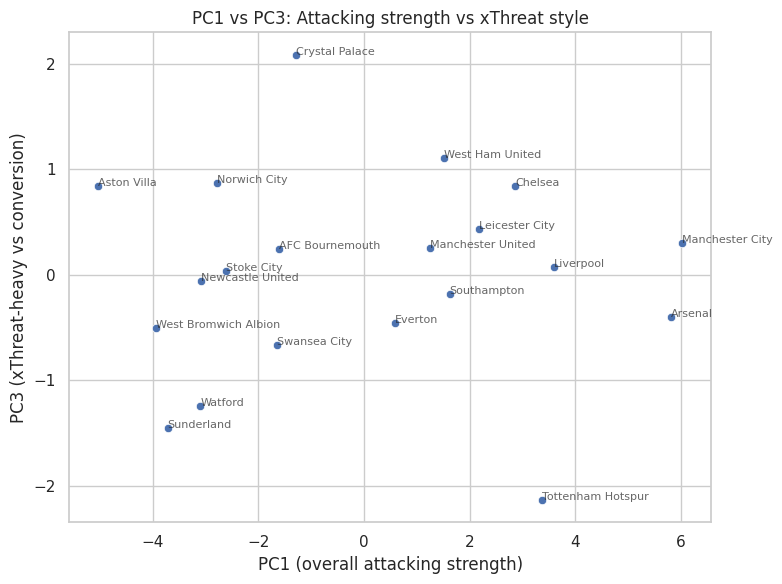

In [14]:
plt.figure(figsize=(8, 6))
ax = sns.scatterplot(
    data=pc_scores,
    x="PC1",
    y="PC3"
)

ax.set_title("PC1 vs PC3: Attacking strength vs xThreat style")
ax.set_xlabel("PC1 (overall attacking strength)")
ax.set_ylabel("PC3 (xThreat-heavy vs conversion)")

# Optional labels again
if "team_name" in pc_scores.columns:
    for _, row in pc_scores.iterrows():
        ax.text(
            row["PC1"],
            row["PC3"],
            str(row["team_name"]),
            fontsize=8,
            alpha=0.7
        )

plt.tight_layout()
plt.show()


In [15]:
# How many teams to show from each end
k = 5

for pc in ["PC1", "PC2", "PC3"]:
    print(f"\n=== Top {k} teams on {pc} ===")
    display(
        pc_scores
        .sort_values(pc, ascending=False)
        [[pc] + id_cols]
        .head(k)
    )

    print(f"\n=== Bottom {k} teams on {pc} ===")
    display(
        pc_scores
        .sort_values(pc, ascending=True)
        [[pc] + id_cols]
        .head(k)
    )



=== Top 5 teams on PC1 ===


,PC1,team_name,team_id
12,6.0295,Manchester City,36
0,5.8135,Arsenal,1
3,3.6039,Liverpool,24
14,3.3816,Tottenham Hotspur,38
11,2.8630,Chelsea,33



=== Bottom 5 teams on PC1 ===


,PC1,team_name,team_id
19,-5.0340,Aston Villa,59
6,-3.9318,West Bromwich Albion,27
17,-3.7192,Sunderland,41
2,-3.1040,Watford,23
13,-3.0924,Newcastle United,37



=== Top 5 teams on PC2 ===


...

,PC2,team_name,team_id
1,-4.1577,Leicester City,22
16,-2.4605,West Ham United,40
10,-1.2752,Crystal Palace,31
14,-0.9001,Tottenham Hotspur,38
17,-0.8865,Sunderland,41



=== Top 5 teams on PC3 ===


,PC3,team_name,team_id
10,2.0850,Crystal Palace,31
16,1.1078,West Ham United,40
18,0.8705,Norwich City,56
19,0.8452,Aston Villa,59
11,0.8421,Chelsea,33



=== Bottom 5 teams on PC3 ===


,PC3,team_name,team_id
14,-2.1319,Tottenham Hotspur,38
17,-1.4487,Sunderland,41
2,-1.2427,Watford,23
5,-0.6691,Swansea City,26
6,-0.5017,West Bromwich Albion,27


### **PCA Component Interpretation (Team Archetypes)**

**PC1 – Overall Attacking Strength**
- High values: teams that generate chances, score goals, create xG, produce shots, and sustain high attacking output.  
- Low values: low-scoring, low-chance, low-threat teams.  
- This axis captures general attacking dominance and match control through chance creation.

**PC2 – Possession / Buildup vs Direct Chance Creation**
- High values: teams that progress the ball through passes, carries, and structured buildup (high passes_for, carries_for, f3_entries_for).  
- Low values: teams that may generate xG and goals but rely more on direct, vertical play rather than controlled possession.  
- This axis separates possession-heavy sides from more direct, transition-oriented teams.

**PC3 – xThreat-Driven Play vs Actual Conversion**
- High values: teams with high xThreat creation but not necessarily proportional goal output.  
- Low values: teams whose output leans more toward converting xG/goals rather than accumulating raw threat value.  
- This axis captures stylistic differences between *threat accumulation* and *goal-focused efficiency*.

